# Experiment 0A: are the twelve decision models ready, and do they read text differently?

Before any feature is used for prediction, 0A checks that every pinned runtime works on the real prepared inputs, and describes what the models return for identical text. This inventory reads saved receipts and cached responses; it runs no model and reads no target.

| Figure | Question | Shows |
|---|---|---|
| 1 · Runtime gates and footprint | Is every runtime ready for full extraction? | contract, known-answer, robustness, token-audit and acceptance gates per model, with peak B200 memory, loading and contract time |
| 2 · Output profiles | Does each model separate texts, and on what scale? | each model's main feature on the inputs answered by all twelve: <span style="color:#6A51A3">binary</span> p(positive), <span style="color:#008B8B">multiclass</span> entropy, <span style="color:#B8860B">regression</span> direction |
| 3 · Pairwise agreement | Do the models carry the same information? | rank agreement (binary, regression) and same-top-class rate (multiclass) for every model pair |
| 4 · Robustness | Do harmless input changes move the features? | total variation under paraphrase, unrelated context, an inserted instruction and reversed options |

Model names keep the same colour in every figure of the project. Figures 2–3 use only identical payloads at the currently pinned versions; historical versions (Jev 1.13) stay in the tables. A small passing pilot is not complete feature creation, and none of these descriptive views measures predictive value: that is Experiment 1.

## 1. Scope and provenance

In [1]:
import sys
from pathlib import Path
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file() and (p / "src").is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
import matplotlib.pyplot as plt
from src.utils.notebook_display import display_local, display_json, display_table
from src.utils.notebook_report import begin_report, report_section, record, finish_report
from src.utils.provenance import provenance
from src.visualize import figures, style
style.apply()
NOTEBOOK = '3. experiment_0/01_before_feature_creation'
begin_report()
save = figures.FigureSaver(NOTEBOOK)
report_section("1. Scope, provenance and saved evidence")
display_json("Notebook execution identity", provenance())


## 2. Runtime gates and footprint

Figure 1 reads every gate from a local receipt: a white square means no receipt was found here, not a failed model. The right panels come from the same contract run on one B200 GPU.

model_id,model,pin,kind,known_answer,robustness,token_audit,accepted,accepted_utc,gpu_name,peak_gpu_gb,load_seconds,contract_seconds,live_requests,configured,staged_receipt,full_bank_tokens,bounded_runtime,semantic_review,complete_feature_datasets,observed_utc,source,source_sha256,staged_manifest
jev,jev-1.14.0,1.14.0,hosted,not_applicable,observed,not_applicable,observed,None,None,NaN,NaN,NaN,NaN,observed,not_applicable,not_applicable,observed,unknown,not assessed here,2026-10-30T08:11:10.580327+00:00,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\3. experiment_0\manifests\before_extraction\jev_smoke.json,71ae96127516c2fe402ee06dcb0e34d9e24f0c33e4b88b049777f4bdb8d9089f,None
liquid,LiquidAI/d1-3B,051bcc464b01b9f92942b364d9586b0ef5912432,open,observed,observed,observed,observed,2026-10-30T13:23:17.387332+00:00,NVIDIA B200,6.538566,4.297721,49.701576,102.0,observed,unknown,unknown,observed,review,not assessed here,2026-10-30T08:21:14.509740+00:00,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\3. experiment_0\manifests\before_extraction\gpu_contracts\liquid_9ec245d2a03d40f9bca2463e96fcd409.json,414b11f1c57492d80fbaf8fac85771a92d70b9c81793e29a84eb0a8e5895b4f5,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\checkpoints\decision_models\liquid\_JEVPFN_CHECKPOINT.json
liquid_lfm3,LiquidAI/d1-2B,cfe5760ff5d5998f91d9ac56bd4b2dbd96996d41,open,observed,observed,observed,observed,2026-10-30T13:23:17.575867+00:00,NVIDIA B200,4.112390,16.702619,60.828091,102.0,observed,unknown,unknown,observed,review,not assessed here,2026-10-30T11:39:19.778468+00:00,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\3. experiment_0\manifests\before_extraction\gpu_contracts\liquid_lfm3_fb5afa385b7948dfab5fb5352524ba42.json,f87cbf10999bb7c3a2b7b027822a128b30ddf8fd684b7a9feec5116ffa650f43,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\checkpoints\decision_models\liquid_lfm3\_JEVPFN_CHECKPOINT.json
perplexity,perplexity-ai/pplx-decider-v1.1-27b,14c9d90137962d300f3de95633f7b6535e80c5ce,open,observed,observed,observed,observed,2026-10-30T13:23:17.448997+00:00,NVIDIA B200,52.857277,31.841778,141.752177,106.0,observed,unknown,unknown,observed,review,not assessed here,2026-10-30T08:41:41.848037+00:00,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\3. experiment_0\manifests\before_extraction\gpu_contracts\perplexity_db1723afd7f846dc8f52dba49770fade.json,f9be1fe46c0e0e17f249829692e60d5463b32fe0942d52fc718652b228d2a504,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\checkpoints\decision_models\perplexity\_JEVPFN_CHECKPOINT.json
cloudflare,Cloudflare/clef-flash,8b2e5fd17c09fd49bc2880b805d5323ec7ff4ff3,open,observed,observed,observed,observed,2026-10-30T13:23:17.474003+00:00,NVIDIA B200,19.913589,12.071956,64.333045,106.0,observed,unknown,unknown,observed,review,not assessed here,2026-10-30T08:49:56.555572+00:00,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\3. experiment_0\manifests\before_extraction\gpu_contracts\cloudflare_b6122293809044ba9d602c99595cc73f.json,693b3f8159968eac8e32de9d0d2acbb194b7beff53e58c24173ab8fafce8bad5,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\checkpoints\decision_models\cloudflare\_JEVPFN_CHECKPOINT.json
intern,internlm/Intern-Decision-4B,0e5e6aa7d6d750e2b1504ba11a8136cb58aeb3cd,open,observed,observed,observed,observed,2026-10-30T13:23:17.485489+00:00,NVIDIA B200,10.032857,23.103771,64.141661,102.0,observed,unknown,unknown,observed,review,not assessed here,2026-10-30T09:01:00.375521+00:00,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\output_JEVPFN\3. experiment_0\manifests\before_extraction\gpu_contracts\intern_d3fea05f63544011859d6a99e819cf50.json,efbbd63f50ecfe417db34f67c301cfe0ac69453efae3f4dd4a8959831f29f8ec,C:\Users\U0152019\PhD Documents\Projects\5. JEVPFN\JEVPFN\checkpoints\decision_models\intern\_JEVPFN_CHECKPOINT.json
strands,StrandsAgents/strands-decider-2B-qw

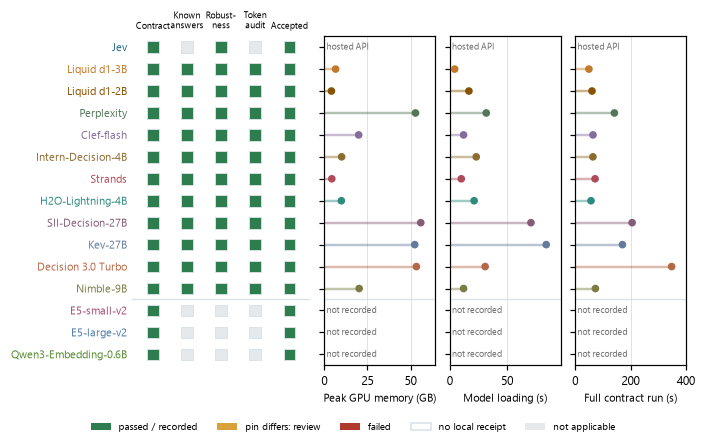

In [2]:
report_section('2. Runtime evidence')
from src.evaluation.notebook_evidence import local_runtime_evidence
from src.visualize.research import runtime_evidence_figure
evidence, token_scope = local_runtime_evidence()
display_table("Runtime pins, receipt provenance and recorded status", evidence, preview_rows=14)
display_json("Exact token audit scope", token_scope)
for fig, name, caption in [runtime_evidence_figure(evidence)]:
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)


## 3. Do the decision models read the same text differently?

All verified cached responses are decoded with the production decoder. Figures 2 and 3 then keep only payloads answered by all twelve models at their pinned versions, so every model sees exactly the same task context, question, options and text. The full cache, including historical settings, is summarized in the table. No target value is read; invalid responses are counted and excluded.

provider,model,task_type,count,mean,std,min,25%,50%,75%,max
cloudflare,Cloudflare/clef-flash,binary_classification,180.0,0.312,0.297,0.016,0.099,0.165,0.478,0.962
cloudflare,Cloudflare/clef-flash,multiclass_classification,459.0,0.658,0.218,0.140,0.492,0.748,0.842,0.961
cloudflare,Cloudflare/clef-flash,regression,819.0,-0.153,0.474,-2.071,-0.294,-0.068,0.025,1.272
decision3,vllm-sr/d3-turbo,binary_classification,108.0,0.245,0.230,0.001,0.061,0.136,0.414,0.771
decision3,vllm-sr/d3-turbo,multiclass_classification,282.0,0.618,0.245,0.001,0.523,0.698,0.790,0.922
decision3,vllm-sr/d3-turbo,regression,510.0,0.247,0.844,-2.704,-0.154,0.217,0.740,2.802
h2o,h2oai/h2o-lightning-4b,binary_classification,108.0,0.154,0.104,0.070,0.088,0.154,0.199,0.801
h2o,h2oai/h2o-lightning-4b,multiclass_classification,282.0,0.576,0.260,0.034,0.401,0.590,0.807,0.982
provider,model,task_type,count,mean,std,min,25%,50%,75%,max
cloudflare,Cloudflare/clef-flash,binary_classification,180.0,0.312,0.297,0.016,0.099,0.165,0.478,0.962


provider,provider,jev,liquid,liquid_lfm3,perplexity,cloudflare,intern,strands,h2o,sii,kev,decision3,nimble
,jev,1.00,0.48,-0.33,-0.27,0.01,-0.56,-0.63,0.47,0.62,0.86,0.87,0.83
,liquid,0.48,1.00,-0.32,-0.38,0.12,-0.28,0.01,0.27,0.51,0.42,0.47,0.39
,liquid_lfm3,-0.33,-0.32,1.00,0.50,0.49,0.21,0.21,0.10,-0.20,-0.17,-0.25,-0.34
,perplexity,-0.27,-0.38,0.50,1.00,0.48,0.50,0.28,0.04,-0.08,-0.12,-0.17,-0.30
,cloudflare,0.01,0.12,0.49,0.48,1.00,0.22,0.18,0.29,0.19,0.06,0.04,0.14
,intern,-0.56,-0.28,0.21,0.50,0.22,1.00,0.70,-0.58,-0.10,-0.71,-0.65,-0.52
,strands,-0.63,0.01,0.21,0.28,0.18,0.70,1.00,-0.60,-0.14,-0.73,-0.70,-0.66
,h2o,0.47,0.27,0.10,0.04,0.29,-0.58,-0.60,1.00,0.16,0.63,0.50,0.49
provider,provider,jev,liquid,liquid_lfm3,perplexity,cloudflare,intern,strands,h2o,sii,kev,decision3,nimble
,jev,1.00,0.48,-0.33,-0.27,0.01,-0.56,-0.63,0.47,0.62,0.86,0.87,0.83


index,jev,liquid,liquid_lfm3,perplexity,cloudflare,intern,strands,h2o,sii,kev,decision3,nimble
jev,1.00,0.48,0.51,0.50,0.58,0.38,0.40,0.60,0.60,0.66,0.56,0.65
liquid,0.48,1.00,0.57,0.33,0.57,0.56,0.48,0.55,0.59,0.43,0.26,0.31
liquid_lfm3,0.51,0.57,1.00,0.37,0.49,0.40,0.47,0.50,0.49,0.57,0.38,0.49
perplexity,0.50,0.33,0.37,1.00,0.51,0.33,0.27,0.51,0.58,0.70,0.74,0.58
cloudflare,0.58,0.57,0.49,0.51,1.00,0.58,0.48,0.66,0.73,0.63,0.44,0.52
intern,0.38,0.56,0.40,0.33,0.58,1.00,0.58,0.51,0.51,0.34,0.19,0.40
strands,0.40,0.48,0.47,0.27,0.48,0.58,1.00,0.47,0.36,0.36,0.24,0.37
h2o,0.60,0.55,0.50,0.51,0.66,0.51,0.47,1.00,0.58,0.63,0.43,0.56
index,jev,liquid,liquid_lfm3,perplexity,cloudflare,intern,strands,h2o,sii,kev,decision3,nimble
jev,1.00,0.48,0.51,0.50,0.58,0.38,0.40,0.60,0.60,0.66,0.56,0.65


provider,provider,jev,liquid,liquid_lfm3,perplexity,cloudflare,intern,strands,h2o,sii,kev,decision3,nimble
,jev,1.00,0.21,0.15,0.87,0.79,0.56,0.27,0.65,0.75,0.80,0.80,0.55
,liquid,0.21,1.00,0.26,0.23,0.27,0.32,0.42,0.22,0.07,0.19,0.15,0.18
,liquid_lfm3,0.15,0.26,1.00,0.09,0.15,0.28,0.10,0.15,0.02,0.11,0.11,0.12
,perplexity,0.87,0.23,0.09,1.00,0.83,0.52,0.28,0.69,0.82,0.89,0.89,0.59
,cloudflare,0.79,0.27,0.15,0.83,1.00,0.58,0.30,0.69,0.64,0.71,0.72,0.51
,intern,0.56,0.32,0.28,0.52,0.58,1.00,0.22,0.70,0.47,0.49,0.50,0.51
,strands,0.27,0.42,0.10,0.28,0.30,0.22,1.00,0.33,0.31,0.31,0.24,0.21
,h2o,0.65,0.22,0.15,0.69,0.69,0.70,0.33,1.00,0.67,0.66,0.61,0.45
provider,provider,jev,liquid,liquid_lfm3,perplexity,cloudflare,intern,strands,h2o,sii,kev,decision3,nimble
,jev,1.00,0.21,0.15,0.87,0.79,0.56,0.27,0.65,0.75,0.80,0.80,0.55


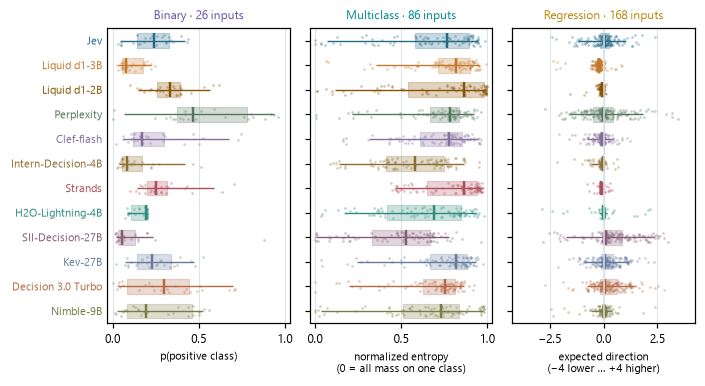

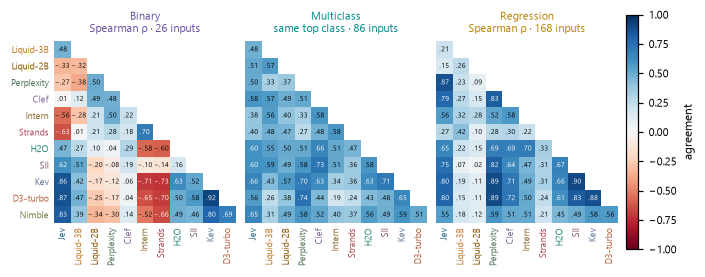

In [3]:
report_section('3. Decision outputs on identical inputs')
from src.evaluation.notebook_evidence import pilot_agreement, pilot_decision_outputs, shared_pilot_outputs
from src.visualize.research import pilot_agreement_figure, pilot_output_figures
pilot = pilot_decision_outputs()
display_table("Cached responses by provider, model version and task", pilot.groupby(["provider", "model", "task_type"]).value.describe().round(3).reset_index())
shared = shared_pilot_outputs(pilot)
agreement = pilot_agreement(shared)
record({"invalid_responses": pilot.attrs.get("invalid_responses", 0), "responses": len(pilot), "shared_inputs_by_task": shared.groupby("task_type").input.nunique().to_dict()}, "Decoded cached responses and identical-input subset")
for task, (matrix, n) in agreement.items():
    display_table(f"Pairwise agreement · {task} · {n} identical inputs", matrix.round(2).reset_index())
for fig, name, caption in [*pilot_output_figures(shared), *pilot_agreement_figure(agreement)]:
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)

## 4. Are the features robust to harmless input changes?

Each model answered the same three real inputs (one per task) unmodified and under interventions that should not change the answer. Figure 4 compares the full probability vectors; an asterisk marks a changed top answer. This is a 0A diagnostic to report, never a criterion for choosing prompts from test results.

provider,source_sha256,probe,total_variation_from_base,same_top_option,maximum_probability_change,expected_direction_change,created_utc,variant,dataset_id
jev,4e1a7325ace61bc8ddc7e35b52aa9ab7cb7359fd9073bc4ed07ac8f63c1818a7,real_BIN_TEXT_FAKE_JOB_POSTING__base,0.00,True,0.00,NaN,2026-10-30T08:12:45.725946+00:00,base,BIN_TEXT_FAKE_JOB_POSTING
jev,4e1a7325ace61bc8ddc7e35b52aa9ab7cb7359fd9073bc4ed07ac8f63c1818a7,real_BIN_TEXT_FAKE_JOB_POSTING__paraphrase,0.04,True,0.04,NaN,2026-10-30T08:12:45.725946+00:00,paraphrase,BIN_TEXT_FAKE_JOB_POSTING
jev,4e1a7325ace61bc8ddc7e35b52aa9ab7cb7359fd9073bc4ed07ac8f63c1818a7,real_BIN_TEXT_FAKE_JOB_POSTING__irrelevant_context,0.17,True,0.17,NaN,2026-10-30T08:12:45.725946+00:00,irrelevant_context,BIN_TEXT_FAKE_JOB_POSTING
jev,4e1a7325ace61bc8ddc7e35b52aa9ab7cb7359fd9073bc4ed07ac8f63c1818a7,real_BIN_TEXT_FAKE_JOB_POSTING__embedded_instruction,0.48,False,0.48,NaN,2026-10-30T08:12:45.725946+00:00,embedded_instruction,BIN_TEXT_FAKE_JOB_POSTING
jev,4e1a7325ace61bc8ddc7e35b52aa9ab7cb7359fd9073bc4ed07ac8f63c1818a7,real_MUL_TEXT_DATA_SCIENTIST_SALARY__base,0.00,True,0.00,NaN,2026-10-30T08:12:45.725946+00:00,base,MUL_TEXT_DATA_SCIENTIST_SALARY
jev,4e1a7325ace61bc8ddc7e35b52aa9ab7cb7359fd9073bc4ed07ac8f63c1818a7,real_MUL_TEXT_DATA_SCIENTIST_SALARY__paraphrase,0.03,True,0.02,NaN,2026-10-30T08:12:45.725946+00:00,paraphrase,MUL_TEXT_DATA_SCIENTIST_SALARY
jev,4e1a7325ace61bc8ddc7e35b52aa9ab7cb7359fd9073bc4ed07ac8f63c1818a7,real_MUL_TEXT_DATA_SCIENTIST_SALARY__irrelevant_context,0.13,True,0.11,NaN,2026-10-30T08:12:45.725946+00:00,irrelevant_context,MUL_TEXT_DATA_SCIENTIST_SALARY
jev,4e1a7325ace61bc8ddc7e35b52aa9ab7cb7359fd9073bc4ed07ac8f63c1818a7,real_MUL_TEXT_DATA_SCIENTIST_SALARY__embedded_instruction,0.15,True,0.11,NaN,2026-10-30T08:12:45.725946+00:00,embedded_instruction,MUL_TEXT_DATA_SCIENTIST_SALARY
provider,source_sha256,probe,total_variation_from_base,same_top_option,maximum_probability_change,expected_direction_change,created_utc,variant,dataset_id
jev,4e1a7325ace61bc8ddc7e35b52aa9ab7cb7359fd9073bc4ed07ac8f63c1818a7,real_BIN_TEXT_FAKE_JOB_POSTING__base,0.000000,True,0.000000,NaN,2026-10-30T08:12:45.725946+00:00,base,BIN_TEXT_FAKE_JOB_POSTING


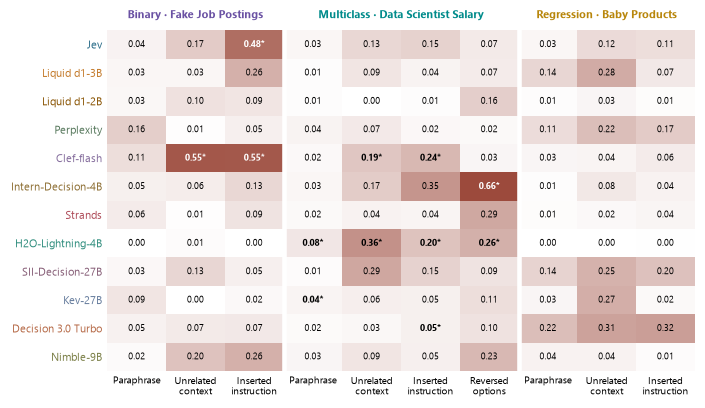

In [4]:
report_section('4. Robustness to harmless input changes')
from src.evaluation.notebook_evidence import prompt_evidence
from src.visualize.research import robustness_matrix_figure
changes, distributions, sources = prompt_evidence()
display_table("Every robustness comparison", changes.drop(columns=["source"]))
display_json("Dated robustness receipts", sources)
for fig, name, caption in robustness_matrix_figure(changes):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)

## 5. What each test establishes

CPU tests check input construction, storage/recovery and exact tokenization. GPU/API contracts check actual response semantics and bounded real-text requests. Neither proves full-dataset predictor feasibility.

In [5]:
report_section('5. What each test establishes')
from src.utils.config import load_yaml
display_json("Configured extraction acceptance gates", load_yaml("experiment_0/debug"))
record("Before extraction: review exact token/window coverage, semantic anchors, sensitivity diagnostics, recoverability, spending/rate limits, storage protection and current source/runtime identities. Section 4 reports sensitivity; 0B checks full features and predictors.", "Interpretation")

## Complete printed report

Everything displayed above is printed in section order. Individual predictions and the full metric store remain available in the referenced evaluation databases.

In [6]:
finish_report(NOTEBOOK, save.summary() + "\nNo fitting, inference or outcome-based method selection was performed.")

3. experiment_0/01_before_feature_creation

1. Scope, provenance and saved evidence


Notebook execution identity
{
  "code_sha256": "87a371d41054a8b6cfe8b2826812ccc1ee1625e2679ec3f53c3a8c68cfd008f2",
  "git_head": "954c93fdb29290e85cb98bf3a374674d466e5ef8",
  "git_dirty": true,
  "tfm_library_pin": "8be0408ef0f6debf7f5d852a49380186d832f1a9 dm-library (remotes/origin/HEAD)\n 26156f36eb7676e8d9050547817346db548b0e85 tfm-library (remotes/origin/HEAD)\n 0ed4ffa89d312b9bb6411681b6a14f81672439f3 vsc-library (remotes/origin/HEAD)",
  "environment": {
    "python": "3.12.10",
    "numpy": "2.5.3",
    "pandas": "2.3.3",
    "PyYAML": "6.0.3",
    "matplotlib": "3.11.2",
    "pyarrow": "25.0.1"
  }
}


2. Runtime evidence


Runtime pins, receipt provenance and recorded status
            model_id                                            model                                      pin    kind   known_answer     robustness    token_audit accepted                     accepted_utc    gpu_name  pe